# Árvore de Decisão

Este notebook responde a pergunta de negócio: a árvore de decisão melhora a explicabilidade e, se sim, isso muda a recomendação do modelo principal?

A lógica é simples:
- avaliar a árvore como modelo interpretable;
- comparar com os modelos já avaliados;
- decidir se a recomendação principal muda ou se a decisão permanece pela melhor performance.


{
  "decision_tree": {
    "accuracy": 0.8079,
    "precision": 0.3846,
    "recall": 0.625,
    "f1": 0.4762,
    "roc_auc": 0.8269
  },
  "logreg_balanced": {
    "accuracy": 0.7948,
    "precision": 0.3729,
    "recall": 0.6875,
    "f1": 0.4835,
    "roc_auc": 0.8384
  },
  "random_forest_balanced": {
    "accuracy": 0.9039,
    "precision": 0.75,
    "recall": 0.4688,
    "f1": 0.5769,
    "roc_auc": 0.9087
  },
  "histgradient_boosting": {
    "accuracy": 0.9127,
    "precision": 0.7727,
    "recall": 0.5312,
    "f1": 0.6296,
    "roc_auc": 0.8886
  }
}


/tmp/ipykernel_165327/3307727944.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="modelo", y="f1", palette="viridis")


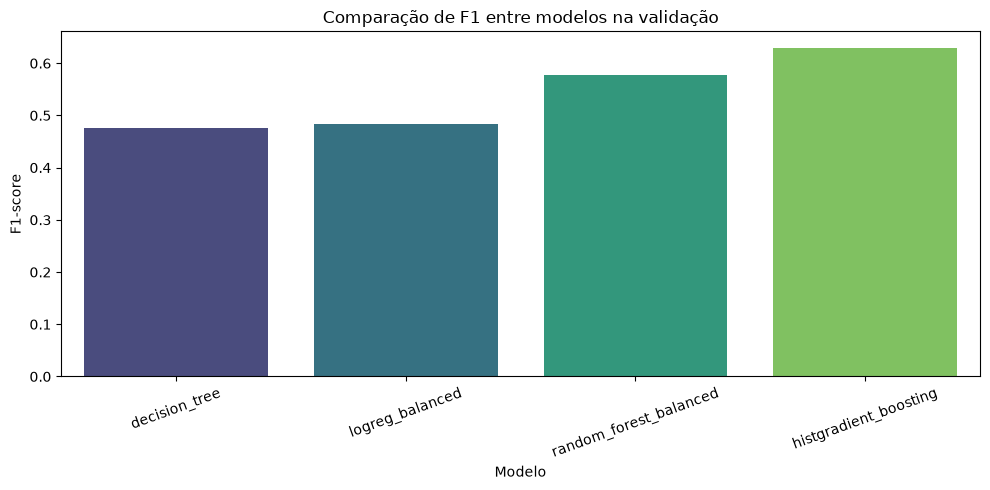

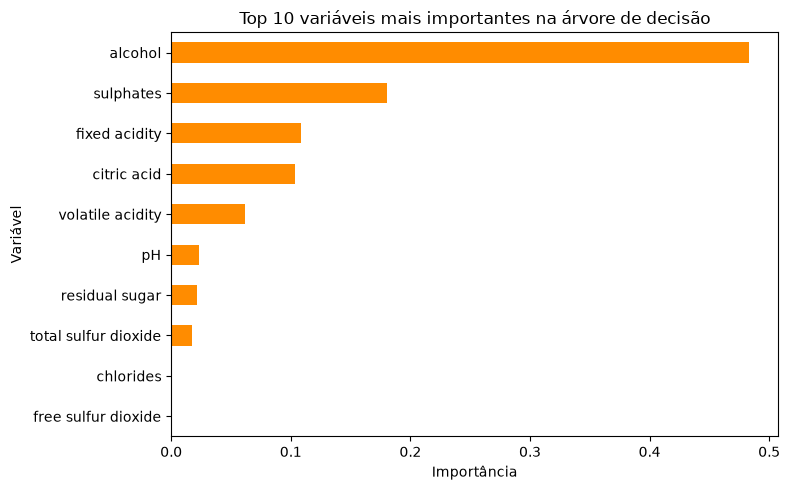

In [4]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

BASE_DIR = Path('..')
DATA_PATH = BASE_DIR / 'data' / 'WineQT.csv'

wine = pd.read_csv(DATA_PATH)
wine["target"] = (wine["quality"] >= 7).astype(int)

feature_cols = [c for c in wine.columns if c not in {'quality', 'target', 'Id'}]
X = wine[feature_cols]
y = wine["target"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "decision_tree": DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced"),
    "logreg_balanced": LogisticRegression(max_iter=4000, class_weight="balanced", random_state=42),
    "random_forest_balanced": RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced_subsample"),
    "histgradient_boosting": HistGradientBoostingClassifier(random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_val)
    results[name] = {
        "accuracy": round(accuracy_score(y_val, pred), 4),
        "precision": round(precision_score(y_val, pred, zero_division=0), 4),
        "recall": round(recall_score(y_val, pred, zero_division=0), 4),
        "f1": round(f1_score(y_val, pred, zero_division=0), 4),
        "roc_auc": round(roc_auc_score(y_val, proba), 4),
    }

print(json.dumps(results, indent=2, ensure_ascii=False))

results_df = pd.DataFrame.from_dict(results, orient="index").reset_index()
results_df = results_df.rename(columns={"index": "modelo"})

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="modelo", y="f1", palette="viridis")
plt.title("Comparação de F1 entre modelos na validação")
plt.xlabel("Modelo")
plt.ylabel("F1-score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced")
model_tree.fit(X_train, y_train)
feature_importance = pd.Series(model_tree.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
feature_importance.sort_values().plot(kind="barh", color="darkorange")
plt.title("Top 10 variáveis mais importantes na árvore de decisão")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()


# Decisão de negócio
#
# A árvore de decisão é útil para explicabilidade e comunicação com stakeholders.
# No entanto, se a métrica decisória for F1/ROC-AUC em um problema desbalanceado, a melhor recomendação
# continua sendo o modelo com melhor performance global, não necessariamente o mais simples.
#
# Conclusão: a árvore pode ser usada como modelo explicável de apoio, mas não altera a conclusão principal
# enquanto o objetivo principal for maximizar a detecção da classe positiva com desempenho robusto.
